# Wine Quality Prediction

Dataset: [Wine Quality Predictiont](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset)

Dataset Description:

The Wine Quality Dataset is a dataset used to analyze and predict wine quality based on physicochemical charateristics. This dataset is commonlt used for machine learning, particularly for classification and regression problems.


|          Feature        |  Data Type |                                                       Description                                                                    |
|-------------------------|------------|--------------------------------------------------------------------------------------------------------------------------------------|
| fixed acidity           |    Float   | Measurinng the total acidity in wine, such as tartaric acid. This affects the wine's acidity and characteristics.                    |
| volatile acidity	      |    Float   | Measures the amount of volatile acids, particularly thar are too high can result in a vinegar-like taste and aroma |
| residual sugar          |    Float   | The amount of sugar remaining in the wine after fermentation is complete. A high value typically a sweeter wine. |
| chlorides               |    Float   | Measuring the salt (chloride) content in wine. High levels can make the wine taste saltier |
| free sulfur dioxide     |    Float   | The amount of sulfur dioxide (SO₂) in its free form, which acts as a preservative and helps prevent oxidation and the growth of microrganisms. |
| total sulfur dioxide    |    Float   | The total amount of sulfur dioxide, both free and bound, in wine. |
| density	              |    Float   | The density of wine. Its value can be influenced by the alcohol and sugar content in the wine. |
| pH                      |    Float   | Acidity level of wine. A lower pH value indicates a more acidic wine, while a higher values indicates a lower acidity level |
| sulphates               |    Float   | The sulfate content in wine can act as an antioxidant and affect the characteristics and stability of the wine |
| alcohol                 |    Float   | The percentage of alcohol content in wine by volume (ABV) |
| quality                 |    Int     | The wine quality score that serves as the target/label in the analysis. The higher the score, the better the wine's quality based on dataset's assessment |
| Id                      |    Int     | Unique number, or typically an identifier, rather than a key feature |

# Preparation

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

## Import Dataset

In [2]:
Wine_df=pd.read_csv('./Dataset/WineQT.csv')
Wine_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


# EDA (Exploratory Data Analysis)

## Data Understanding

In [3]:
Wine_df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


In [4]:
Wine_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [5]:
Wine_df.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [6]:
Wine_df.duplicated().sum()

0

In [7]:
row, col=Wine_df.shape
print("Number of Row of Dataset:", row)
print("Number of Column of Dataset:", col)

Number of Row of Dataset: 1143
Number of Column of Dataset: 13


## Data Visualization

### Boxplot of Numeric Feature

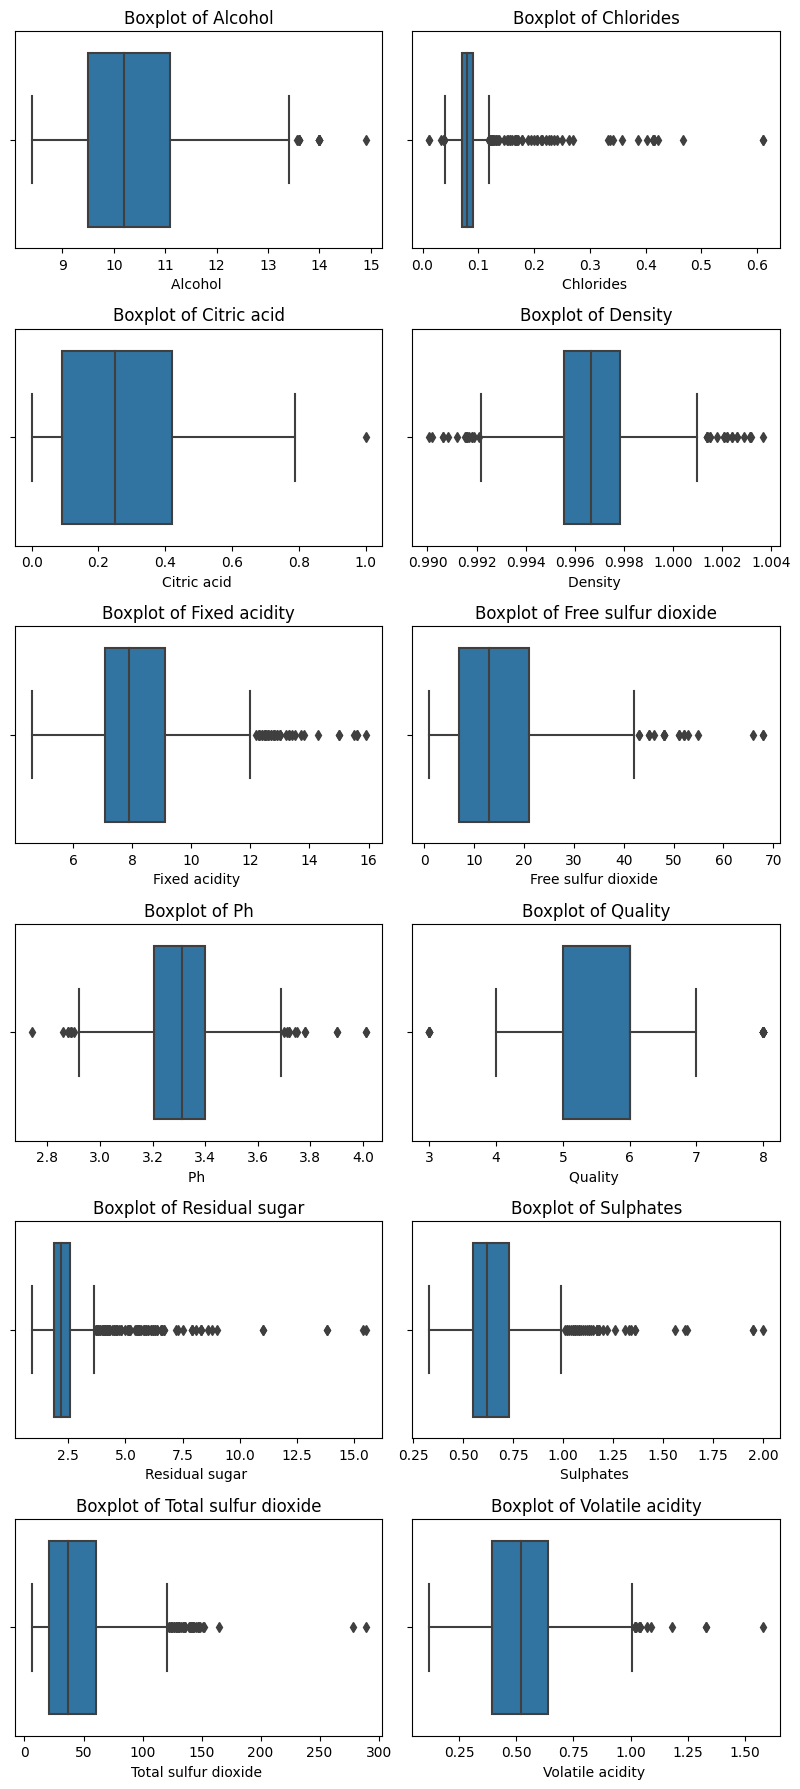

In [8]:
num_cols=Wine_df.select_dtypes(include=['number']).columns.difference(['Id'])

fig, axes=plt.subplots(6,2, figsize=(8,18))
axes=axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=Wine_df, x=col, ax=axes[i])
    axes[i].set_xlabel(f'{col.capitalize()} ')
    axes[i].set_title(f'Boxplot of {col.capitalize()}')

plt.tight_layout()
plt.show()

### Histogram of Numeric Feature

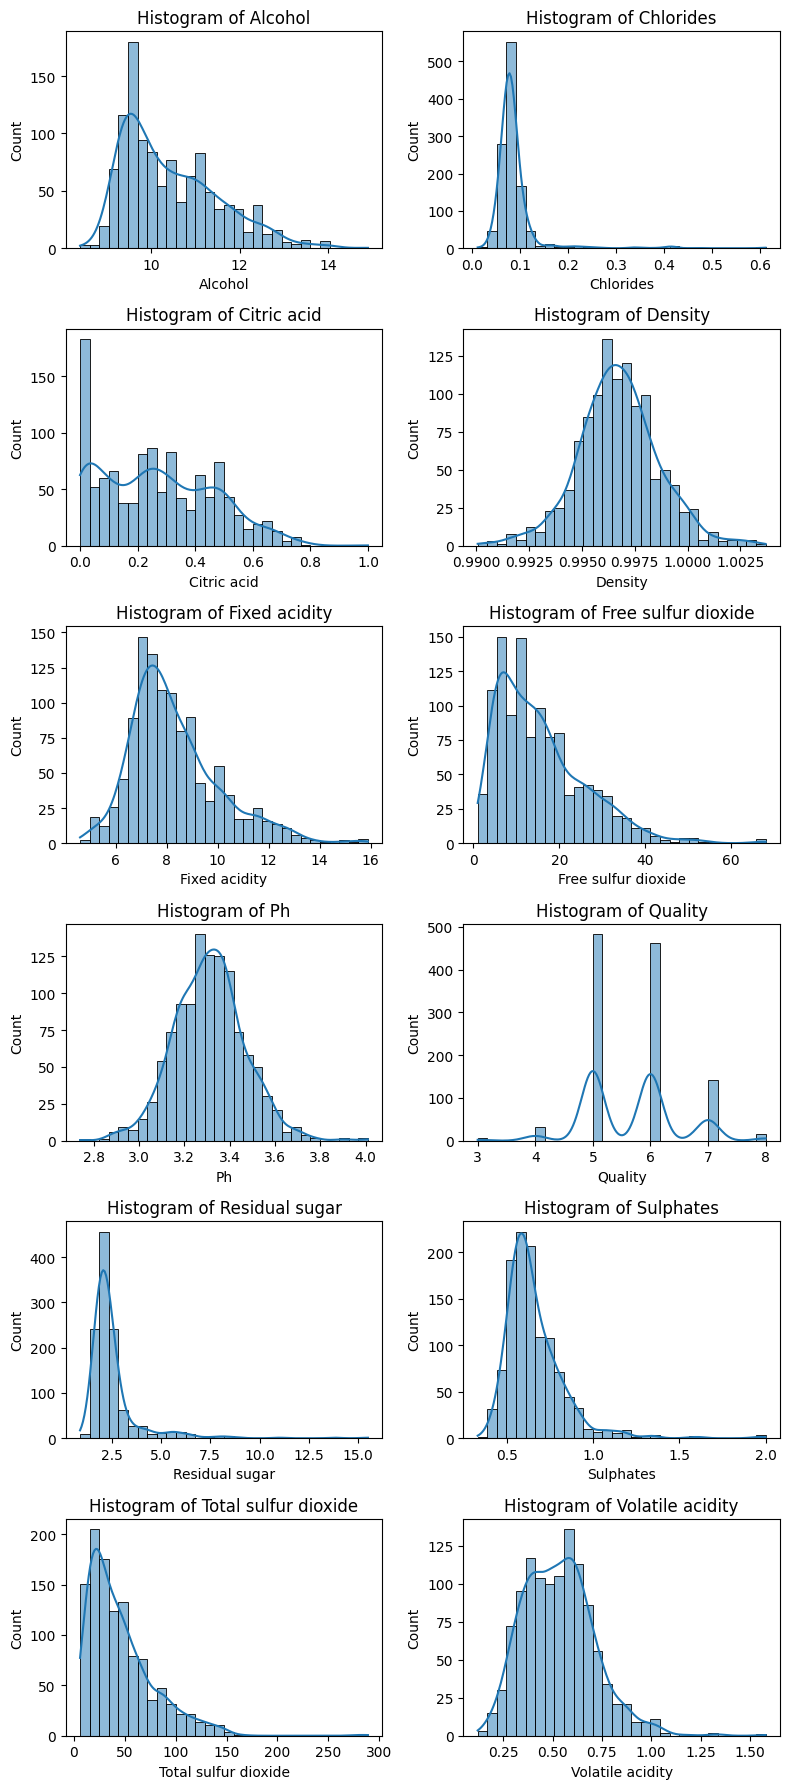

In [9]:
fig, axes=plt.subplots(6,2, figsize=(8,18))
axes=axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=Wine_df[col], bins=30, kde=True, edgecolor='black', ax=axes[i])
    axes[i].set_xlabel(col.capitalize())
    axes[i].set_title(f'Histogram of {col.capitalize()}')

plt.tight_layout()
plt.show()

# Data Preprocessing

## Drop Irrelevant Column

In [10]:
Wine_df=Wine_df.drop(columns=['Id'], axis=1)

# Data Visualization

### Heatmap of Numerical Feature

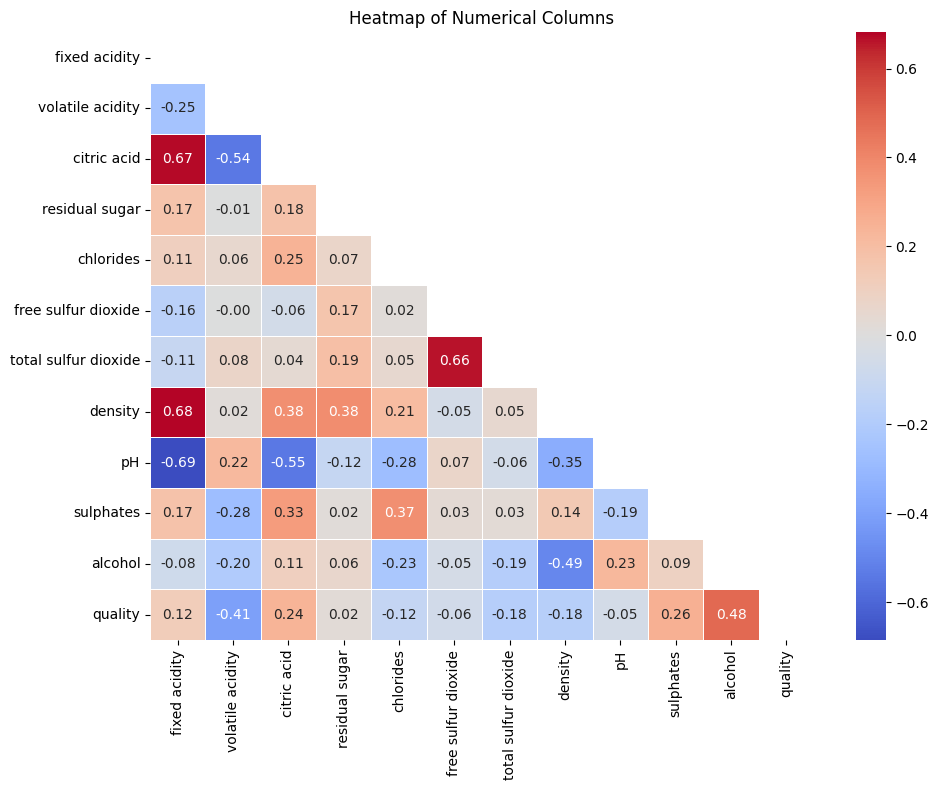

In [11]:
num_cols=Wine_df
corr_num=num_cols.corr()
mask=np.triu(np.ones_like(corr_num, dtype=bool))
plt.figure(figsize=(10,8))
sns.heatmap(corr_num, annot=True, cmap='coolwarm', linewidths=0.5, mask=mask, fmt='.2f')
plt.title('Heatmap of Numerical Columns')
plt.tight_layout()
plt.show()

## Data Preparation

### Split Data Training and Data Test

In [12]:
X=Wine_df.drop(columns='quality')
y=Wine_df['quality']

In [13]:
X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.2, random_state=42)
print(f"Training Data Shape, X_train:{X_train.shape}, y_train:{y_train.shape}")
print(f"Test Data Shape, X_test: {X_test.shape}, y_test:{y_test.shape}")

Training Data Shape, X_train:(914, 11), y_train:(914,)
Test Data Shape, X_test: (229, 11), y_test:(229,)


### Normalization

In [14]:
scaler=StandardScaler()
scaler.fit(X_train)

X_train=scaler.transform(X_train)
X_test=scaler.transform(X_test)

## Modelling

### Linear Regression

In [15]:
LR=LinearRegression().fit(X_train, y_train)
eval_lr=LR.predict(X_test)

mae_lr=mean_absolute_error(y_test, eval_lr)
mse_lr=mean_squared_error(y_test, eval_lr)
r2_lr=r2_score(y_test, eval_lr)

In [16]:
Result_df=({
    "MAE":[mae_lr],
    "MSE":[mse_lr],
    "R2 Score":[r2_lr]
})
Result_df=pd.DataFrame(Result_df, index=['Linear Regression'])
Result_df

,MAE,MSE,R2 Score
Linear Regression,0.47734,0.380032,0.317069


### Random Forest 

In [17]:
RF=RandomForestRegressor().fit(X_train, y_train)
eval_rf=RF.predict(X_test)

mae_rf=mean_absolute_error(y_test, eval_rf)
mse_rf=mean_squared_error(y_test, eval_rf)
r2_rf=r2_score(y_test, eval_rf)

In [18]:
Result_df.loc['Random Forest']=[mae_rf, mse_rf, r2_rf]
Result_df

,MAE,MSE,R2 Score
Linear Regression,0.477340,0.380032,0.317069
Random Forest,0.419651,0.304523,0.452762


### Decision Tree 

In [19]:
DT=DecisionTreeRegressor().fit(X_train, y_train)
eval_dt=DT.predict(X_test)

mae_dt=mean_absolute_error(y_test, eval_dt)
mse_dt=mean_squared_error(y_test, eval_dt)
r2_dt=r2_score(y_test, eval_dt)

In [20]:
Result_df.loc['Decision Tree']=[mae_dt, mse_dt, r2_dt]
Result_df

,MAE,MSE,R2 Score
Linear Regression,0.477340,0.380032,0.317069
Random Forest,0.419651,0.304523,0.452762
Decision Tree,0.510917,0.606987,-0.090775


### SVM 

In [21]:
SVM=SVR().fit(X_train, y_train)
eval_svm=SVM.predict(X_test)

mae_svm=mean_absolute_error(y_test, eval_svm)
mse_svm=mean_squared_error(y_test, eval_svm)
r2_svm=r2_score(y_test, eval_svm)

In [22]:
Result_df.loc['SVM']=[mae_svm, mse_svm, r2_svm]
Result_df

,MAE,MSE,R2 Score
Linear Regression,0.477340,0.380032,0.317069
Random Forest,0.419651,0.304523,0.452762
Decision Tree,0.510917,0.606987,-0.090775
SVM,0.402766,0.301549,0.458106


### GBR (Gradient Bossting Regressor)

In [23]:
GBR=GradientBoostingRegressor().fit(X_train, y_train)
eval_gbr=GBR.predict(X_test)

mae_gbr=mean_absolute_error(y_test, eval_gbr)
mse_gbr=mean_squared_error(y_test, eval_gbr)
r2_gbr=r2_score(y_test, eval_gbr)

In [24]:
Result_df.loc['Gradient Boosting']=[mae_gbr, mse_gbr, r2_gbr]
Result_df

,MAE,MSE,R2 Score
Linear Regression,0.477340,0.380032,0.317069
Random Forest,0.419651,0.304523,0.452762
Decision Tree,0.510917,0.606987,-0.090775
SVM,0.402766,0.301549,0.458106
Gradient Boosting,0.446108,0.329243,0.408339


### XGBoost

In [27]:
XGB=xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.8,
    random_state=42
).fit(X_train, y_train)

eval_xgb=XGB.predict(X_test)
mae_xgb=mean_absolute_error(y_test, eval_gbr)
mse_xgb=mean_squared_error(y_test, eval_xgb)
r2_xgb=r2_score(y_test, eval_xgb)


In [28]:
Result_df.loc['XGBoost']=[mae_xgb, mse_xgb, r2_xgb]
Result_df

,MAE,MSE,R2 Score
Linear Regression,0.477340,0.380032,0.317069
Random Forest,0.419651,0.304523,0.452762
Decision Tree,0.510917,0.606987,-0.090775
SVM,0.402766,0.301549,0.458106
Gradient Boosting,0.446108,0.329243,0.408339
XGBoost,0.446108,0.330661,0.405791



# Conclusion

- After doing data modeling using the wine dataset, it can be concluded that when the wine dataset is used in regression analysis, the target value becomes a floating-point number, and it appears that the Random Forest model has the highest R² value compared to the other models, at 0.452762. However, that model failed to detect patterns in the data, so the model with the lowest R² value is the Decision Tree.
